# TP3 — Generative Models: VAE and GAN

---

## Objectives

By the end of this session, you will be able to:
1. Implement a **Variational Autoencoder** end-to-end, including the encoder, the reparameterization trick, and the ELBO loss derived in CM5
2. Implement and compare **two formulations of the GAN generator loss** — the original minimax objective and the non-saturating heuristic — and observe the vanishing-gradient phenomenon directly
3. Examine a learned **latent space** through sampling and interpolation
4. Argue, on the basis of your own experimental results, how VAEs and GANs trade off training stability against sample quality

## Prerequisites (CM5)
- Discriminative versus generative models, autoencoders, latent space
- VAE: probabilistic generative model, reparameterization trick, closed-form KL divergence between two Gaussian distributions
- GAN: adversarial training, the minimax objective, training instability (mode collapse, vanishing gradients)

## Task Overview

Part 1 constructs a VAE from first principles on Fashion-MNIST. Part 2 provides a functioning
GAN (the network architecture and training loop are already implemented); the objective is to
implement **two formulations of the generator loss** and conduct a controlled comparison between
them. Part 3 requires a comparative analysis of VAE and GAN as alternative solutions to the same
problem.

## Deliverables
**Submit your GitHub repository link to [xchang3@slb.com](mailto:xchang3@slb.com) before the deadline.**
```
your-repo/
├── tp3-vae-gan.ipynb   ← all cells executed top-to-bottom, outputs visible
└── report.pdf          ← 1–2 pages, maximum 2 pages
```

**Deadline**: **23:59, November 18th**

The report should address the following sections:
1. **Part 1 — VAE**: respond to the questions at the end of Part 1
2. **Part 2 — GAN Generator Loss Comparison**: complete the Results and Analysis section
3. **Part 3 — VAE vs. GAN**: complete the comparison table and respond to the final questions

Results must be discussed analytically: cite specific values, refer to figures by their titles,
and relate observations to the theoretical framework established in CM5.

## Session Structure

| Part | Content |
|------|---------|
| 0 · Setup | Imports and device configuration |
| 1 · VAE | Data preparation (`[0, 1]`), encoder/decoder, reparameterization, ELBO loss, latent space exploration |
| 2 · GAN | Data preparation (`[-1, 1]`), minimax versus non-saturating generator loss, controlled comparison |
| 3 · VAE vs. GAN | Comparative summary |

## Part 0 — Setup

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

BATCH_SIZE = 128

Using device: cpu


---

## Part 1 — Variational Autoencoder

**Objective**: to train a model capable of generating novel Fashion-MNIST items, rather than
merely reproducing the training set. This section implements an **encoder**, which maps an
image to a probability distribution over a low-dimensional latent space, and a **decoder**,
which maps a latent vector back to a 28×28 image. Once trained, sampling an arbitrary point
from the latent space and decoding it should yield a recognizable, albeit blurred, item of
clothing.

### 1.1 — Loading Fashion-MNIST for the VAE

The Fashion-MNIST dataset from TP1 is reused in this section. The VAE's reconstruction loss
(Section 1.3) is a binary cross-entropy, which treats each pixel as a Bernoulli probability and
is therefore defined only on `[0, 1]`. The decoder accordingly terminates in a `Sigmoid`
activation, and the default `ToTensor()` scaling — which already maps pixel values to `[0, 1]`
— requires no further adjustment. No implementation is required in this cell; execute it to
proceed.

In [ ]:
vae_transform = transforms.ToTensor()  # pixels already in [0, 1], matches the decoder's Sigmoid
vae_train_set = datasets.FashionMNIST(root='./data', train=True, download=True, transform=vae_transform)
vae_test_set  = datasets.FashionMNIST(root='./data', train=False, download=True, transform=vae_transform)
vae_train_loader = DataLoader(vae_train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
vae_test_loader  = DataLoader(vae_test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Train: {len(vae_train_set)} | Test: {len(vae_test_set)}')

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 169kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.19MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.6MB/s]

Train: 60000 | Test: 10000


### 1.2 — Encoder, Decoder, and Reparameterization

**Architecture overview**:

Encoder — maps an image to the parameters of a latent distribution:
```
Image (28x28=784) → [Linear 784→400, ReLU] → h (400)
                                                 ├─→ [Linear 400→latent_dim] → mu
                                                 └─→ [Linear 400→latent_dim] → log_var = log(sigma^2)
```

Reparameterize — samples a latent vector from that distribution:
```
z = mu + sigma * epsilon,   where epsilon ~ N(0, I)
```

Decoder — maps the sampled latent vector back to an image:
```
z (latent_dim=20) → [Linear latent_dim→400, ReLU] → [Linear 400→784, Sigmoid] → Reconstruction (28x28)
```

The hidden representation produced by the encoder feeds into **two distinct linear heads**
(`fc_mu`, `fc_log_var`) rather than one; this is the defining characteristic of the variational
formulation, as each input is mapped to the parameters of a distribution over the latent space
rather than to a single point. Note that `fc_log_var` outputs `log_var = log(sigma^2)` rather
than `sigma` directly, for reasons of numerical stability: since `sigma` must remain strictly
positive, an unconstrained linear layer cannot output it directly without an additional
activation to enforce positivity; predicting its logarithm instead allows the network to output
any real number, and exponentiating it appropriately recovers a valid, positive `sigma`. The
decoder mirrors the encoder's dimensions in reverse, mapping a sampled `z` back to a complete
image.

Complete the following `# TODO` sections:
- `encoder`: a small MLP mapping a flattened 784-pixel image to a 400-dimensional hidden
  representation
- `fc_mu` / `fc_log_var`: two linear heads mapping this hidden representation to the mean and
  log-variance of the approximate posterior `q(z|x)`
- `decoder`: a small MLP mapping a latent vector back to a 784-pixel image (`Sigmoid` output,
  since pixel values lie in `[0, 1]`)
- `reparameterize`: the reparameterization trick from CM5 — `z = mu + sigma * epsilon`, with
  `epsilon ~ N(0, I)` (derive `sigma` from `log_var` using the relationship described above)

In [ ]:
LATENT_DIM = 20

class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 400),  # TODO
            nn.ReLU(),  # TODO
        )
        self.fc_mu = nn.Linear(400, latent_dim)       # TODO
        self.fc_log_var = nn.Linear(400, latent_dim)  # TODO

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 400),  # TODO
            nn.ReLU(),  # TODO
            nn.Linear(400, 784),  # TODO
            nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_log_var(h)

    def reparameterize(self, mu, log_var):
        # TODO: implement the reparameterization trick (see the architecture overview above)
        std = torch.exp(0.5 * log_var) # sigma = exp(0.5 * log(sigma^2))
        eps = torch.randn_like(std) # epsilon ~ N(0, 1)
        return mu + std * eps # z = mu + sigma * epsilon

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        return self.decode(z), mu, log_var

vae_model = VAE().to(device)
n_params = sum(p.numel() for p in vae_model.parameters())  # total trainable parameter count, as a sanity check on model size
print(f'VAE parameters: {n_params:,}')

VAE parameters: 652,824


### 1.3 — ELBO Loss

The VAE objective comprises a reconstruction term and a KL-divergence term (CM5). The
reconstruction term is a binary cross-entropy between the input and its reconstruction. The KL
term is the closed-form expression for `KL(q(z|x) || N(0, I))` derived in CM5:

$$D_{KL} = -\frac{1}{2}\sum_{j}\left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

Complete the `# TODO` sections below.

In [ ]:
def vae_loss(recon_x, x, mu, log_var):
    # recon_x: the decoder's output (reconstructed image), x: the original input image
    # TODO: reconstruction term — binary cross-entropy between recon_x and x, summed over pixels
    #       (torch.nn.functional, imported here as F, provides a ready-made BCE function)
    recon_loss = F.binary_cross_entropy(recon_x, x, reduction="sum")

    # TODO: closed-form KL divergence between N(mu, sigma^2) and N(0, I) (CM5 derivation)
    kl_loss = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())

    # Both terms above are summed over the whole batch, so their scale grows with batch size.
    # Dividing by the batch size here converts the total into a per-sample average loss.
    return (recon_loss + kl_loss) / x.size(0)

### 1.4 — Training Loop

Adapt the training loop introduced in TP1/TP2 to this setting, and complete the `# TODO`
sections.

In [ ]:
def train_vae(model, loader, optimizer, num_epochs):
    model.train()
    history = []
    for epoch in range(num_epochs):
        total_loss = 0.0
        for x, _ in loader:
            x = x.to(device)

            # TODO: zero the gradients, forward pass through the model (get recon, mu, log_var),
            #       compute the loss with vae_loss, backward pass, and take an optimizer step
            # 1. Clear gradients
            optimizer.zero_grad()

            # 2. Forward pass
            recon, mu, log_var = model(x)

            # 3. Compute loss
            loss = vae_loss(recon, x, mu, log_var)

            # 4. Backward pass
            loss.backward()

            # 5. Optimizer step
            optimizer.step()

            total_loss += loss.item() * x.size(0)
        avg_loss = total_loss / len(loader.dataset)
        history.append(avg_loss)
        print(f'Epoch {epoch+1}/{num_epochs} — ELBO loss: {avg_loss:.2f}')
    return history

Epoch 1/15 — ELBO loss: 260.70
Epoch 2/15 — ELBO loss: 252.20
Epoch 3/15 — ELBO loss: 248.42
Epoch 4/15 — ELBO loss: 246.35
Epoch 5/15 — ELBO loss: 245.14
Epoch 6/15 — ELBO loss: 244.18
Epoch 7/15 — ELBO loss: 243.54
Epoch 8/15 — ELBO loss: 243.07
Epoch 9/15 — ELBO loss: 242.61
Epoch 10/15 — ELBO loss: 242.24
Epoch 11/15 — ELBO loss: 241.91
Epoch 12/15 — ELBO loss: 241.65
Epoch 13/15 — ELBO loss: 241.37
Epoch 14/15 — ELBO loss: 241.17
Epoch 15/15 — ELBO loss: 240.94


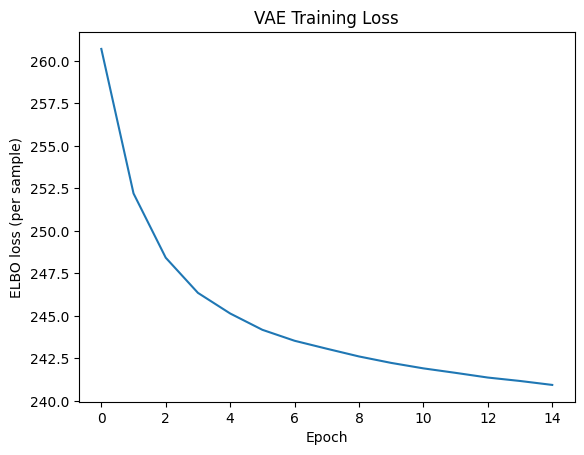

In [ ]:
NUM_EPOCHS_VAE = 15

vae_optimizer = optim.Adam(vae_model.parameters(), lr=1e-3)
vae_history = train_vae(vae_model, vae_train_loader, vae_optimizer, NUM_EPOCHS_VAE)

plt.plot(vae_history)
plt.xlabel('Epoch'); plt.ylabel('ELBO loss (per sample)')
plt.title('VAE Training Loss')
plt.show()

### 1.5 — Reconstructions

A reconstruction encodes a real test image into `(mu, log_var)`, samples `z` via the
reparameterization trick, and decodes that `z` back into an image — effectively asking "how much
of this specific input survived the trip through the latent bottleneck?" This is different from
the generation experiments in 1.6, where `z` has no real image behind it at all. No
implementation is required in this cell; execute it to examine the quality of the VAE's
reconstructions of real images.

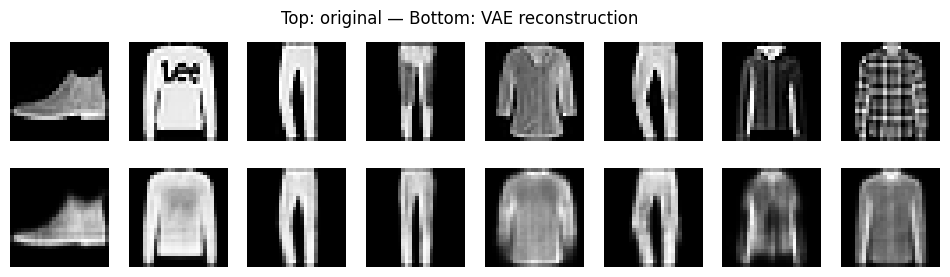

In [ ]:
vae_model.eval()
with torch.no_grad():
    x, _ = next(iter(vae_test_loader))
    x = x[:8].to(device)
    recon, _, _ = vae_model(x)

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(x[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(recon[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Original')
axes[1, 0].set_ylabel('Reconstruction')
plt.suptitle('Top: original — Bottom: VAE reconstruction')
plt.show()

### 1.6 — Latent Space Exploration

Two experiments examine whether the latent space is genuinely continuous and structured — the
property the KL term is intended to confer (CM5) — rather than merely a lookup table of
memorized points:

- **(a) Sampling from the prior**: decode points drawn directly from `N(0, I)`, with no
  corresponding real image. This corresponds to the actual generation scenario: at inference
  time, no input is available to encode, so the decoder must produce plausible output for
  *arbitrary* latent points, not only those near an encoded real image. If the latent space
  contains gaps, randomly sampled points fall within them and decode to implausible output.
- **(b) Interpolation**: encode two *real* images to obtain `mu1` and `mu2`, then decode points
  along the line segment connecting them. This examines whether nearby latent points decode to
  visually similar images: a smooth, gradual transition between the two inputs indicates that
  the latent space is locally continuous, whereas an abrupt discontinuity indicates that it is
  not.

Experiment (a) is provided; complete the `# TODO` in (b).

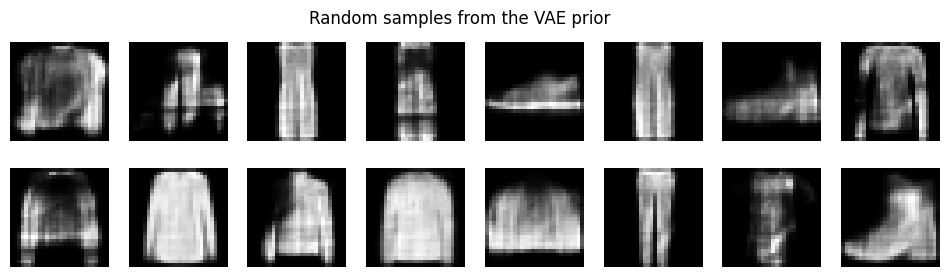

In [ ]:
vae_model.eval()
with torch.no_grad():
    # (a) points sampled straight from the prior N(0, I) — no real image behind them
    z = torch.randn(16, LATENT_DIM).to(device)
    samples = vae_model.decode(z).cpu()

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i, 0], cmap='gray')
    ax.axis('off')
plt.suptitle('Random samples from the VAE prior')
plt.show()

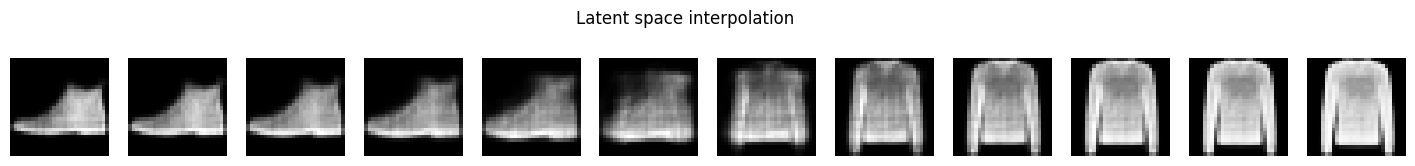

In [ ]:
def interpolate(model, img1, img2, steps=12):
    model.eval()
    with torch.no_grad():
        # (b) mu1, mu2: latent means of two *real* encoded images (not random points)
        mu1, _ = model.encode(img1.unsqueeze(0).to(device))
        mu2, _ = model.encode(img2.unsqueeze(0).to(device))

        # TODO: build `steps` evenly spaced points on the straight line between mu1 and mu2
        #       (alpha going from 0 to 1), then decode each one
        alphas = torch.linspace(0, 1, steps, device=device).unsqueeze(1)  # shape: (steps, 1)
        z_interp = (1 - alphas) * mu1 + alphas * mu2                      # shape: (steps, latent_dim)

        images = model.decode(z_interp)
    return images.cpu()

img_a, _ = vae_test_set[0]
img_b, _ = vae_test_set[1]
interp_images = interpolate(vae_model, img_a, img_b)

fig, axes = plt.subplots(1, len(interp_images), figsize=(18, 2))
for i, ax in enumerate(axes):
    ax.imshow(interp_images[i, 0], cmap='gray')
    ax.axis('off')
plt.suptitle('Latent space interpolation')
plt.show()

---

**Section 1 of the report** is based on Part 1:
- Compare the reconstructions (1.5) to the random prior samples (1.6). Which are sharper, and
  why is this asymmetry consistent with what the encoder and the prior each have access to?
- Does the interpolation transition smoothly between the two images, or does it change abruptly
  partway through? What does this indicate about the structure the KL term imposes on the
  latent space?
- Suppose the loss were changed from `recon_loss + kl_loss` to `recon_loss + beta * kl_loss`
  with `beta > 1` (this is the β-VAE formulation). What effect would this have on reconstruction
  sharpness? This need not be run experimentally — reason from the two competing objectives in
  the ELBO.

---

## Part 2 — GAN: Comparing Two Generator Losses

**Objective**: to generate Fashion-MNIST items with a second kind of model — this time via
adversarial training rather than a reconstruction objective. A **Generator** network learns to
map random noise to images, while a **Discriminator** network learns to tell those generated
images apart from real ones; the two are trained against each other, each trying to improve at
the other's expense. Rather than building this adversarial setup from scratch, the network
architectures, the discriminator loss, and the training loop are provided below; the task is to
implement two generator losses and conduct a controlled comparison between them.

### 2.1 — Loading Fashion-MNIST for the GAN

The generator terminates in a `Tanh` activation, producing output in `[-1, 1]` rather than
`[0, 1]`. This is not a mathematical requirement in the sense that the VAE's Sigmoid/BCE
pairing is: a GAN has no per-pixel probability to compute, so a Sigmoid generator trained on
`[0, 1]` data would function equally well. `Tanh` combined with zero-centered `[-1, 1]` data is
simply the convention established since the DCGAN paper (Radford et al., 2016), motivated by
improved training stability, as the generator's output is not then systematically biased toward
one end of the range. A second copy of the dataset is accordingly loaded, rescaled with
`Normalize((0.5,), (0.5,))`. No implementation is required in this cell; execute it to proceed.

In [ ]:
gan_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
gan_train_set = datasets.FashionMNIST(root='./data', train=True, download=True, transform=gan_transform)
gan_train_loader = DataLoader(gan_train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

print(f'Train: {len(gan_train_set)}')

Train: 60000


### 2.2 — Generator and Discriminator (provided)

**Architecture overview**:

Generator — maps a noise vector to an image:
```
z (latent_dim=64) → [Linear 64→256, LeakyReLU] → [Linear 256→512, LeakyReLU] → [Linear 512→784, Tanh] → Image (28x28)
```

Discriminator — maps an image to a realness probability:
```
Image (28x28=784) → [Linear 784→512, LeakyReLU] → [Linear 512→256, LeakyReLU] → [Linear 256→1, Sigmoid] → D(x) ∈ (0, 1)
```

No implementation is required in this cell. These architectures, and the training setup
surrounding them, are provided so that the comparison conducted in 2.3–2.5 isolates the effect
of the loss function from that of network design or GAN-specific training heuristics.

In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 784), nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1), nn.Sigmoid(),
        )

    def forward(self, x):
        return self.net(x)

### 2.3 — Generator Loss: Minimax versus Non-saturating

Complete the three `# TODO` loss functions below (CM5). `discriminator_loss` is the same
regardless of which generator loss is used:

- **Discriminator**: maximizes `log(D(x)) + log(1 - D(G(z)))` (equivalently, minimizes its
  negation)
- **Minimax generator** (Goodfellow et al., 2014): the generator minimizes `log(1 - D(G(z)))`
- **Non-saturating generator**: the generator instead minimizes `-log(D(G(z)))` (equivalently,
  maximizes `log(D(G(z)))`)

`d_real` is `D(x)` for a batch of real images; `d_fake` is `D(G(z))` for a batch of generated
images.

Note the `eps = 1e-8` term added before each `log(...)` call — this does not appear in the CM5
formulas, which are written for exact probabilities. In practice, `D`'s `Sigmoid` output can
round to exactly `0.0` or `1.0` in floating-point arithmetic, and `log(0)` is `-inf`, which would
propagate `NaN` gradients through the whole network. Adding a small `eps` keeps the argument of
`log` strictly positive without noticeably changing its value otherwise; this is a standard
numerical-stability safeguard, not a change to the mathematical objective.

In [ ]:
def discriminator_loss(d_real, d_fake):
    # TODO: discriminator maximizes log(D(x)) + log(1 - D(G(z))); return the quantity it
    #       minimizes (the negation of that, averaged over the batch)
    eps = 1e-8
    return -torch.mean(torch.log(d_real + eps) + torch.log(1.0 - d_fake + eps))

def generator_loss_minimax(d_fake):
    # TODO: original minimax formulation — the generator minimizes log(1 - D(G(z)))
    eps = 1e-8
    return torch.mean(torch.log(1.0 - d_fake + eps))

def generator_loss_nonsaturating(d_fake):
    # TODO: non-saturating heuristic — the generator minimizes -log(D(G(z)))
    eps = 1e-8
    return -torch.mean(torch.log(d_fake + eps))

### 2.4 — Training Loop

Each batch performs **two separate optimizer steps**: a **Discriminator step** (update `D` only,
using both real images and the current fake ones) followed by a **Generator step** (update `G`
only, using a freshly generated batch of fakes). This loop accepts the generator loss function as
a parameter, so the identical loop trains either variant below; the only difference between the
two runs in 2.5 is which `generator_loss_*` function is passed in.

Complete the forward-pass `# TODO` sections in both steps. The `zero_grad()` / `backward()` /
`step()` boilerplate around them is provided unchanged. In the Discriminator step, decide
whether `discriminator(...)` should receive `fake` as-is or `fake.detach()` — be prepared to
explain your choice (hint: think about which network's parameters `d_optimizer.step()` actually
updates, and whether backpropagating into the generator during this step would serve any
purpose).

In [ ]:
def train_gan(generator, discriminator, generator_loss_fn, loader, num_epochs, latent_dim):
    g_optimizer = optim.Adam(generator.parameters(), lr=1e-4, betas=(0.5, 0.999))
    d_optimizer = optim.Adam(discriminator.parameters(), lr=1e-4, betas=(0.5, 0.999))

    history = {'g_loss': [], 'd_loss': [], 'd_of_g_z': []}
    for epoch in range(num_epochs):
        g_losses, d_losses, d_g_z_values = [], [], []
        for real, _ in loader:
            real = real.to(device)
            batch_size = real.size(0)

            # --- Discriminator step: updates D only ---
            z = torch.randn(batch_size, latent_dim, device=device)
            # TODO: generate a batch of fakes with the generator, then score both the real
            #       batch and the fake batch with the discriminator (d_real, d_fake)
            fake = generator(z)
            d_real = discriminator(real)
            d_fake = discriminator(fake.detach())
            d_loss = discriminator_loss(d_real, d_fake)

            d_optimizer.zero_grad()
            d_loss.backward()
            d_optimizer.step()

            # --- Generator step: updates G only, using a fresh batch of fakes ---
            z = torch.randn(batch_size, latent_dim, device=device)
            # TODO: generate a fresh batch of fakes, score them with the discriminator
            #       (d_fake_for_g), then compute the generator loss with generator_loss_fn
            fake = generator(z)
            d_fake_for_g = discriminator(fake)
            g_loss = generator_loss_fn(d_fake_for_g)

            g_optimizer.zero_grad()
            g_loss.backward()
            g_optimizer.step()

            g_losses.append(g_loss.item())
            d_losses.append(d_loss.item())
            d_g_z_values.append(d_fake_for_g.mean().item())

        history['g_loss'].append(float(np.mean(g_losses)))
        history['d_loss'].append(float(np.mean(d_losses)))
        history['d_of_g_z'].append(float(np.mean(d_g_z_values)))
        print(f"Epoch {epoch+1}/{num_epochs} — G loss: {history['g_loss'][-1]:.3f} | "
              f"D loss: {history['d_loss'][-1]:.3f} | D(G(z)): {history['d_of_g_z'][-1]:.3f}")
    return history

### 2.5 — Controlled Comparison

Both runs use identical architecture, hyperparameters, and random seed; the sole difference is
the generator loss function. No implementation is required; execute the cell.

In [ ]:
NUM_EPOCHS_GAN = 40
LATENT_DIM_GAN = 64

torch.manual_seed(42)
G_minimax = Generator(LATENT_DIM_GAN).to(device)
D_minimax = Discriminator().to(device)
history_minimax = train_gan(G_minimax, D_minimax, generator_loss_minimax,
                             gan_train_loader, NUM_EPOCHS_GAN, LATENT_DIM_GAN)

torch.manual_seed(42)
G_ns = Generator(LATENT_DIM_GAN).to(device)
D_ns = Discriminator().to(device)
history_ns = train_gan(G_ns, D_ns, generator_loss_nonsaturating,
                        gan_train_loader, NUM_EPOCHS_GAN, LATENT_DIM_GAN)

Epoch 1/40 — G loss: -0.328 | D loss: 0.545 | D(G(z)): 0.260
Epoch 2/40 — G loss: -0.142 | D loss: 0.522 | D(G(z)): 0.117
Epoch 3/40 — G loss: -0.081 | D loss: 0.332 | D(G(z)): 0.071
Epoch 4/40 — G loss: -0.110 | D loss: 0.501 | D(G(z)): 0.087
Epoch 5/40 — G loss: -0.086 | D loss: 0.349 | D(G(z)): 0.073
Epoch 6/40 — G loss: -0.117 | D loss: 0.521 | D(G(z)): 0.092
Epoch 7/40 — G loss: -0.152 | D loss: 0.556 | D(G(z)): 0.118
Epoch 8/40 — G loss: -0.163 | D loss: 0.608 | D(G(z)): 0.131
Epoch 9/40 — G loss: -0.162 | D loss: 0.585 | D(G(z)): 0.131
Epoch 10/40 — G loss: -0.199 | D loss: 0.680 | D(G(z)): 0.150
Epoch 11/40 — G loss: -0.215 | D loss: 0.687 | D(G(z)): 0.164
Epoch 12/40 — G loss: -0.226 | D loss: 0.745 | D(G(z)): 0.176
Epoch 13/40 — G loss: -0.231 | D loss: 0.732 | D(G(z)): 0.176
Epoch 14/40 — G loss: -0.251 | D loss: 0.774 | D(G(z)): 0.192
Epoch 15/40 — G loss: -0.255 | D loss: 0.767 | D(G(z)): 0.196
Epoch 16/40 — G loss: -0.280 | D loss: 0.834 | D(G(z)): 0.211
Epoch 17/40 — G l

Plot the Generator Loss and `D(G(z))` curves for both runs side by side, so they can be
compared directly on the same axes.

`D(G(z))` is the quantity to focus on when comparing the two runs: unlike the generator loss
value, its meaning (a probability that `D` assigns to a fake sample being real) doesn't depend
on which loss formula was used to train `G`, so it is directly comparable between the minimax
and non-saturating runs — and it is exactly the variable CM5's gradient-coefficient derivation
is written in terms of.

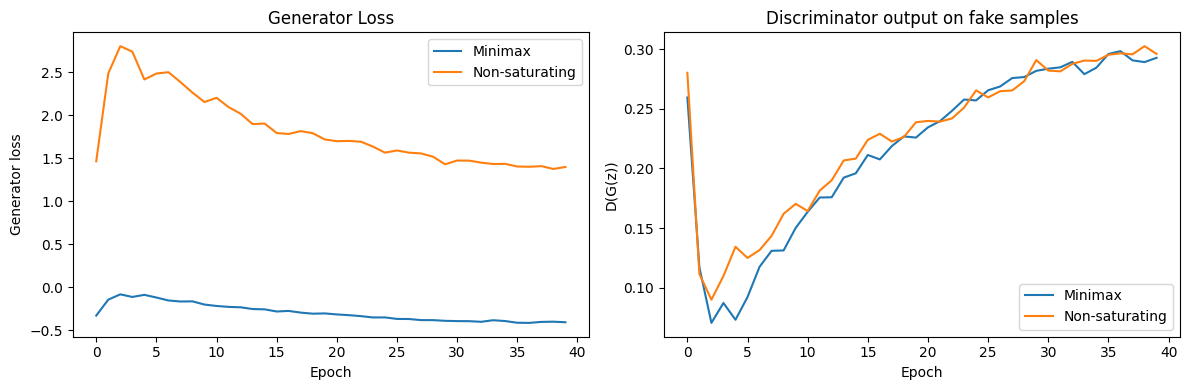

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_minimax['g_loss'], label='Minimax')
axes[0].plot(history_ns['g_loss'], label='Non-saturating')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Generator loss'); axes[0].legend()
axes[0].set_title('Generator Loss')

axes[1].plot(history_minimax['d_of_g_z'], label='Minimax')
axes[1].plot(history_ns['d_of_g_z'], label='Non-saturating')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('D(G(z))'); axes[1].legend()
axes[1].set_title('Discriminator output on fake samples')
plt.tight_layout()
plt.show()

Generate a grid of samples from each trained generator, so their visual quality and diversity
can be compared directly.

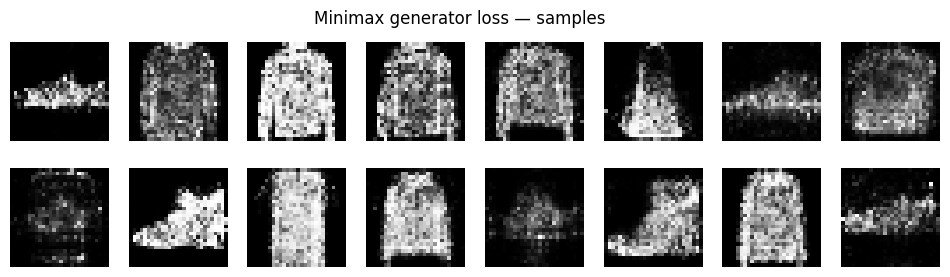

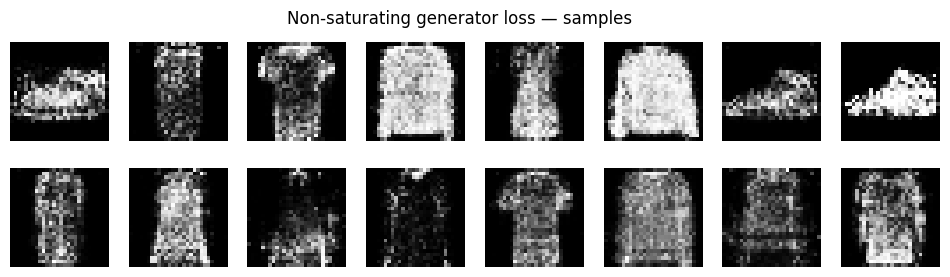

In [ ]:
def show_samples(generator, latent_dim, title, n=16):
    generator.eval()
    with torch.no_grad():
        z = torch.randn(n, latent_dim, device=device)
        samples = generator(z).cpu()
    fig, axes = plt.subplots(2, 8, figsize=(12, 3))
    for i, ax in enumerate(axes.flat):
        ax.imshow(samples[i, 0] * 0.5 + 0.5, cmap='gray')
        ax.axis('off')
    plt.suptitle(title)
    plt.show()

show_samples(G_minimax, LATENT_DIM_GAN, 'Minimax generator loss — samples')
show_samples(G_ns, LATENT_DIM_GAN, 'Non-saturating generator loss — samples')

---

**Section 2 of the report** is based on this comparison, and constitutes the Results and
Analysis section to be completed:
- Examine the Generator Loss and `D(G(z))` plots for both runs. Describe what you observe, and
  analyze why the two losses behave the way they do.
- Compare the generated samples produced by both losses. Does the run exhibiting a flatter or
  more erratic generator loss curve also produce visibly inferior or less diverse samples?
- Goodfellow et al. prove that the global optimum of the minimax objective corresponds to the
  true data distribution, yet the non-saturating version is used almost universally in
  practice. Reconcile these two facts in two to three sentences.

---

## Part 3 — VAE versus GAN

**Section 3 of the report**: on the basis of the observations from Parts 1 and 2, complete the
following comparison table, justifying each entry with a specific observation from your own
experiments — a numerical value, a curve shape, or a visual description of a sample grid,
rather than a generic statement drawn from the literature:

| Dimension | VAE | GAN |
|---|---|---|
| Training stability | | |
| Generated sample sharpness | | |
| Latent space structure / controllability | | |
| Does the loss value track sample quality? | | |

Then address the following:
- If a generative model were required whose loss could be trusted as a stopping criterion
  without visual inspection of samples, which would you select, and why?
- Which failure mode — blurred reconstructions (VAE) or mode collapse/instability (GAN) — would
  be more acceptable in a hypothetical application of your choosing, and why?
- The VAE's decoder and the GAN's generator are both plain MLPs, yet the VAE produces blur and
  the GAN produces speckled noise. What in each model's training signal explains this
  difference?